# Nonlinear system identification: Lorenz '63

Learn the chaotic Lorenz '63 system from sparse, noisy data, following
Galioto & Gorodetsky (2020), Sec. 6.6.1: 100 measurements of all three
states over 10 s, with noise standard deviation 2, starting on the attractor.

- **dynamics**: $x_k = \Psi(x_{k-1}; \theta_{1:3}) + \xi_k$, $\xi_k \sim \mathcal{N}(0, \mathrm{diag}(s_1^2, s_2^2, s_3^2))$,
  where $\Psi$ integrates the Lorenz ODE over one 0.1 s interval
- **observations**: $y_k = x_k + \eta_k$, $\eta_k \sim \mathcal{N}(0, s_\eta^2 I)$

There are seven unknowns: $\theta = (\theta_1, \theta_2, \theta_3, \log s_1, \log s_2, \log s_3, \log s_\eta)$.
With nonlinear dynamics the likelihood $p(y_{1:n} \mid \theta)$ has no closed
form, so a nonlinear filter approximates it with the predict / update
recursion from the filtering examples.

Process noise is what makes a chaotic system learnable from 10 s of data: it
lets the filter correct the trajectory instead of requiring one simulation to
match all the data. Learning the noise level is delicate, though. Joint
optimization tends to stop at a high-noise local optimum, where the data are
explained as noise. The section on process noise shows a continuation strategy
that avoids this.

Runtime: about half an hour, mostly the optimization and DRAM sections.
DRAM needs `pip install bside[mcmc]`.

In [1]:
import math

import torch
import matplotlib.pyplot as plt

import bside
from mcmc_samplers import DelayedRejectionAdaptiveMetropolis

torch.manual_seed(0)

## Model and data

The dynamics map is a module whose `update(params)` hook reads $\theta_{1:3}$.
Written with `unbind(-1)`, it accepts a batch of parameter vectors, so many
values of $\theta$ can be evaluated in one filter pass. The noise covariances
are `CholeskyMatrix` objects with diagonal masks: $\theta_{4:6}$ are the
per-state log standard deviations of the process noise, and $\theta_7$ is
shared by all three measurement noise variances.

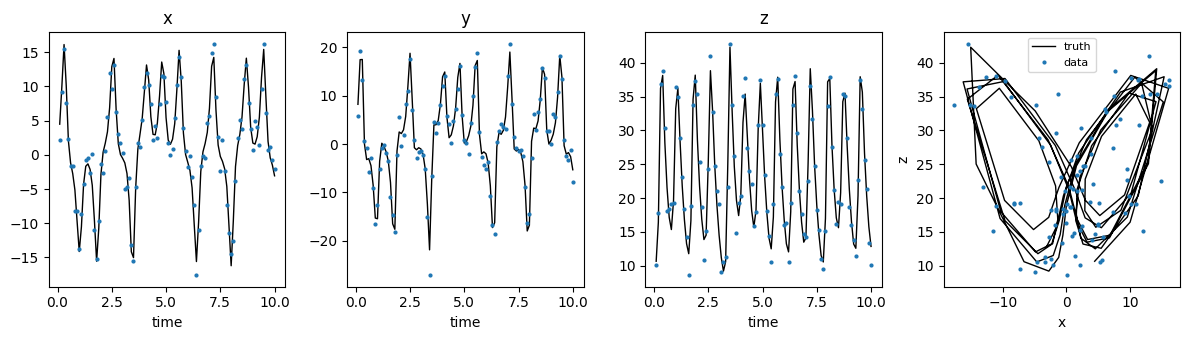

In [2]:
DT, SUBSTEPS, n = 0.1, 5, 100


class Lorenz63(torch.nn.Module):
    def __init__(self, theta):
        super().__init__()
        self.theta = theta

    def update(self, params):
        if params is not None:
            self.theta = params[..., :3]

    def vector_field(self, x):
        s, r, b = self.theta.unbind(-1)
        x1, x2, x3 = x.unbind(-1)
        return torch.stack([s * (x2 - x1), x1 * (r - x3) - x2, x1 * x2 - b * x3], dim=-1)

    def forward(self, x, u=None):
        h = DT / SUBSTEPS
        for _ in range(SUBSTEPS):  # RK4
            k1 = self.vector_field(x)
            k2 = self.vector_field(x + h / 2 * k1)
            k3 = self.vector_field(x + h / 2 * k2)
            k4 = self.vector_field(x + h * k3)
            x = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        return x


theta_dyn_true = torch.tensor([10.0, 28.0, 8.0 / 3.0])
x0 = torch.tensor([2.0181, 3.5065, 11.8044])
truth_model = bside.NonlinearModel(Lorenz63(theta_dyn_true), in_dim=3, out_dim=3)
x_true = truth_model.predict(x0, T=n)
y = x_true + 2.0 * torch.randn_like(x_true)
data = bside.Data(y=y)
init_dist = bside.FilteringDistribution(mean=x0, cov=torch.eye(3))

diag = torch.eye(3, dtype=torch.bool)
Sigma = bside.CholeskyMatrix(torch.eye(3), mask=diag, indices=torch.tensor([3, 4, 5]))
Gamma = bside.CholeskyMatrix(torch.eye(3), mask=diag, indices=torch.tensor([6, 6, 6]))
model = bside.SSM(
    xdim=3, ydim=3,
    dynamics=bside.NonlinearAdditiveModel(f=Lorenz63(theta_dyn_true.clone()), noise_cov=Sigma, in_dim=3, out_dim=3),
    observations=bside.LinearGaussianModel(model=bside.IdentityModel(3), noise_cov=Gamma),
)


def log_prior(theta, tau=10.0):
    """Flat on theta_1:3; half-normal(tau) on each variance, written for log-std parameters."""
    v = torch.exp(2 * theta[..., 3:])
    return (-0.5 * (v / tau) ** 2 + torch.log(2 * v)).sum(-1)


ukf = bside.UnscentedKalmanFilter(model)
posterior = bside.Posterior(ukf, data, init_dist, prior=log_prior)

t = torch.arange(1, n + 1) * DT
fig = plt.figure(figsize=(12, 3.5))
for i, name in enumerate('xyz'):
    ax = fig.add_subplot(1, 4, i + 1)
    ax.plot(t, x_true[:, i], 'k', lw=1)
    ax.plot(t, y[:, i], '.', color='C0', ms=4)
    ax.set_title(name)
    ax.set_xlabel('time')
ax = fig.add_subplot(1, 4, 4)
ax.plot(x_true[:, 0], x_true[:, 2], 'k', lw=1, label='truth')
ax.plot(y[:, 0], y[:, 2], '.', color='C0', ms=4, label='data')
ax.set_xlabel('x')
ax.set_ylabel('z')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Likelihood from two filters

Profile $\log p(y \mid \theta)$ over $\theta_2$ ($\rho$), with the other
parameters at their true values and a small process noise. The UKF gives a
smooth deterministic approximation. The particle filter gives a noisy but
unbiased estimate.

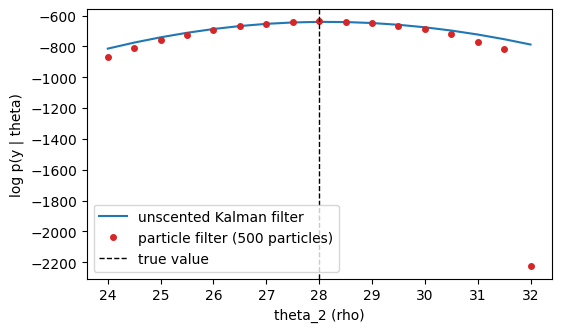

In [3]:
pf = bside.ParticleFilter(model, n_particles=500)
base = torch.cat([theta_dyn_true, torch.full((3,), math.log(0.3)), torch.tensor([math.log(2.0)])])
rhos = torch.linspace(24.0, 32.0, 17)
grid = base.repeat(len(rhos), 1)
grid[:, 1] = rhos

with torch.no_grad():
    ll_ukf = posterior.log_likelihood(grid)                          # one batched UKF pass
    ll_pf = torch.stack([-pf.nlog_marginal_likelihood(data, init_dist, params=theta) for theta in grid])

plt.figure(figsize=(6, 3.5))
plt.plot(rhos, ll_ukf, 'C0-', label='unscented Kalman filter')
plt.plot(rhos, ll_pf, 'C3o', ms=4, label='particle filter (500 particles)')
plt.axvline(28.0, color='k', ls='--', lw=1, label='true value')
plt.xlabel('theta_2 (rho)')
plt.ylabel('log p(y | theta)')
plt.legend()
plt.show()

## Learning the process noise

Start four optimizations from poor guesses of $\theta_{1:3}$, with unit process
and measurement noise (a batch of four, run in one pass).

**Joint MAP.** Optimizing all seven parameters at once stops at large process
noise. There the filter attributes the misfit to noise, so the likelihood
barely responds to the dynamics parameters.

**Continuation** (`noise_continuation`). Fix the process noise at a decreasing
sequence of levels, fit the remaining parameters at each level starting from
the previous fit, and record the best log posterior reached at each level.
Large noise smooths the landscape, so the early fits move the dynamics into
the right basin; smaller noise then sharpens them. Finally, all parameters are
freed and refined from the best level.

joint MAP 0   theta_1:3 = [ 8.88 24.    2.4 ]  process sd = [0.7  2.99 1.81]  measurement sd = 1.71  log posterior = -717.3


joint MAP 1   theta_1:3 = [11.28 31.46  2.73]  process sd = [1.07 2.5  1.78]  measurement sd = 1.90  log posterior = -732.2


joint MAP 2   theta_1:3 = [ 8.25 18.08  2.09]  process sd = [0.85 5.   2.87]  measurement sd = 2.22  log posterior = -828.0


joint MAP 3   theta_1:3 = [ 9.42 25.9   2.86]  process sd = [0.68 1.48 2.57]  measurement sd = 1.63  log posterior = -687.6


continuation 0 theta_1:3 = [ 9.87 28.2   2.63]  process sd = [0.29 0.15 0.18]  measurement sd = 1.80  log posterior = -639.7


continuation 1 theta_1:3 = [ 9.87 28.2   2.63]  process sd = [0.29 0.15 0.18]  measurement sd = 1.81  log posterior = -639.7


continuation 2 theta_1:3 = [ 9.41 25.6   2.53]  process sd = [0.61 1.91 1.32]  measurement sd = 1.70  log posterior = -684.8


continuation 3 theta_1:3 = [ 9.87 28.2   2.63]  process sd = [0.29 0.15 0.18]  measurement sd = 1.81  log posterior = -639.7


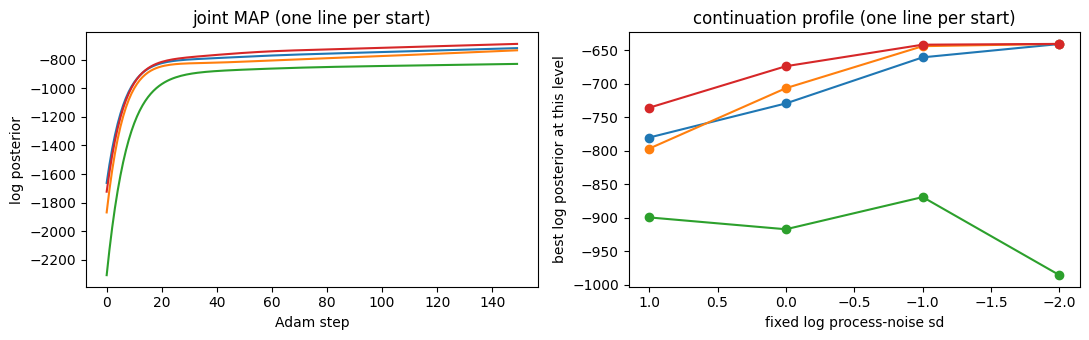

In [4]:
starts = torch.tensor([[5.0, 20.0, 1.0], [15.0, 35.0, 4.0], [8.0, 15.0, 2.0], [12.0, 22.0, 5.0]])
theta0 = torch.cat([starts, torch.zeros(4, 3), torch.zeros(4, 1)], dim=-1)

theta_joint, trace = bside.map_estimate(posterior, theta0, n_steps=150, lr=0.05)

levels = [1.0, 0.0, -1.0, -2.0]
profile = bside.noise_continuation(posterior, theta0, noise_indices=[3, 4, 5], levels=levels,
                                   n_steps=50, lr=0.05, final_steps=100)
theta_hat = profile.theta[posterior(profile.theta).argmax()]


def describe(name, theta):
    lp = posterior(theta).item()
    print(f'{name:<13} theta_1:3 = {theta[:3].numpy().round(2)}  process sd = {theta[3:6].exp().numpy().round(2)}  '
          f'measurement sd = {theta[6].exp().item():.2f}  log posterior = {lp:.1f}')


with torch.no_grad():
    for k in range(len(starts)):
        describe(f'joint MAP {k}', theta_joint[k])
    for k in range(len(starts)):
        describe(f'continuation {k}', profile.theta[k])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(trace)
axes[0].set_xlabel('Adam step')
axes[0].set_ylabel('log posterior')
axes[0].set_title('joint MAP (one line per start)')
axes[1].plot(levels, profile.log_posteriors, 'o-')
axes[1].set_xlabel('fixed log process-noise sd')
axes[1].set_ylabel('best log posterior at this level')
axes[1].set_title('continuation profile (one line per start)')
axes[1].invert_xaxis()
fig.tight_layout()
plt.show()

In this run three of the four starts reach the same low-noise optimum. The
third (green, initial rho = 15, far from 28) stays in a poor region at every
fixed noise level, and the final joint refinement only partly recovers it.
That is still much better than plain joint MAP, but not guaranteed. More steps
per level, finer levels, or simply more starts (they cost little as a batch)
make the continuation more reliable.

## Posterior sampling with DRAM

Start DRAM at the continuation estimate.

acceptance rate: 95.7%
  theta_1:   9.804 +/- 0.219   (true 10.000)
  theta_2:  28.187 +/- 0.122   (true 28.000)
  theta_3:   2.629 +/- 0.038   (true 2.667)
  log s_1:  -1.507 +/- 0.166
  log s_2:  -1.785 +/- 0.311


  log s_3:  -1.952 +/- 0.211
log s_eta:   0.590 +/- 0.037   (true 0.693)


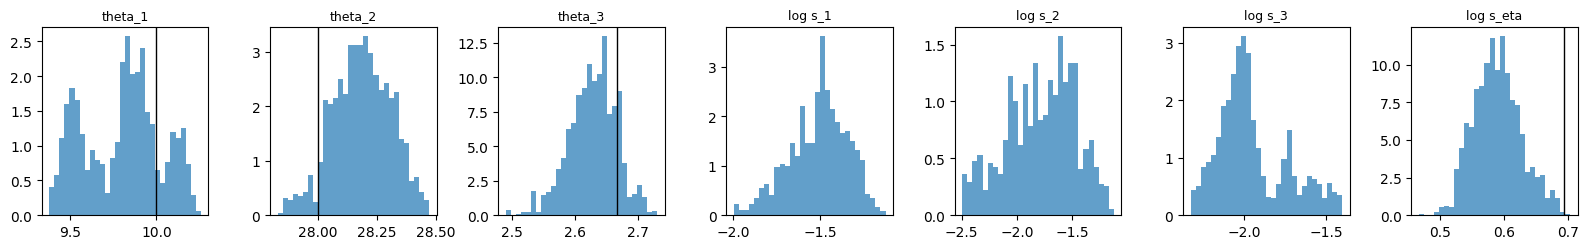

In [5]:
dram = DelayedRejectionAdaptiveMetropolis(target=posterior, x0=theta_hat, cov=1e-3 * torch.eye(7))
with torch.no_grad():
    samples, _ = dram(1500)
samples = samples[300:]

names = ['theta_1', 'theta_2', 'theta_3', 'log s_1', 'log s_2', 'log s_3', 'log s_eta']
truth = [10.0, 28.0, 8.0 / 3.0, None, None, None, math.log(2.0)]
print(f'acceptance rate: {100 * dram.acceptance_ratio:.1f}%')
fig, axes = plt.subplots(1, 7, figsize=(16, 2.6))
for i, ax in enumerate(axes):
    ax.hist(samples[:, i], bins=30, density=True, color='C0', alpha=0.7)
    if truth[i] is not None:
        ax.axvline(truth[i], color='k', lw=1)
    ax.set_title(names[i], fontsize=9)
    print(f'{names[i]:>9}: {samples[:, i].mean():7.3f} +/- {samples[:, i].std():.3f}' +
          ('' if truth[i] is None else f'   (true {truth[i]:.3f})'))
fig.tight_layout()
plt.show()

## Prediction

Simulate the learned dynamics (posterior mean of $\theta_{1:3}$) from the same
initial condition. The trajectories separate after a few seconds, as they must
for a chaotic system. The long-run behaviour is what the data can identify:
the learned model reproduces the attractor (compare the paper's Fig. 18).

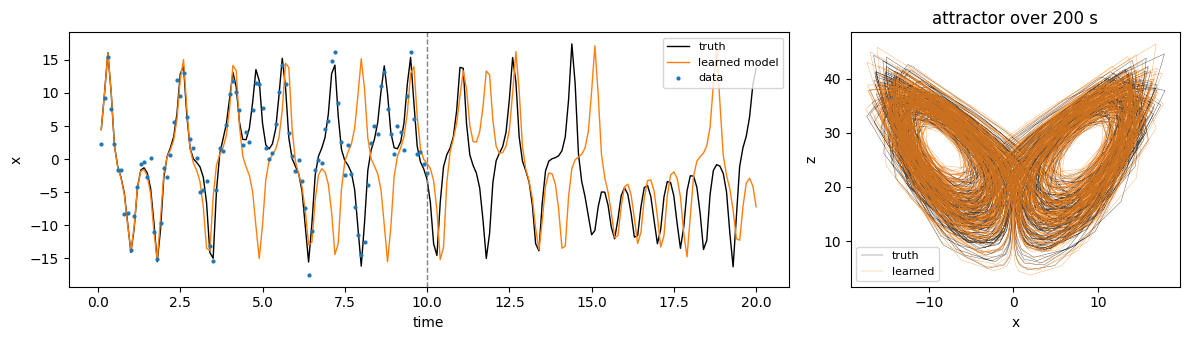

In [6]:
theta_mean = samples[:, :3].mean(0)
learned = bside.NonlinearModel(Lorenz63(theta_mean), in_dim=3, out_dim=3)
T_long = 2000  # 200 s
with torch.no_grad():
    true_long = truth_model.predict(x0, T=T_long)
    learned_long = learned.predict(x0, T=T_long)

t_long = torch.arange(1, T_long + 1) * DT
fig = plt.figure(figsize=(12, 3.5))
ax = fig.add_subplot(1, 3, (1, 2))
window = t_long <= 20
ax.plot(t_long[window], true_long[window, 0], 'k', lw=1, label='truth')
ax.plot(t_long[window], learned_long[window, 0], 'C1', lw=1, label='learned model')
ax.plot(t, y[:, 0], '.', color='C0', ms=4, label='data')
ax.axvline(n * DT, color='gray', ls='--', lw=1)
ax.set_xlabel('time')
ax.set_ylabel('x')
ax.legend(fontsize=8)
ax = fig.add_subplot(1, 3, 3)
ax.plot(true_long[:, 0], true_long[:, 2], 'k', lw=0.3, alpha=0.7, label='truth')
ax.plot(learned_long[:, 0], learned_long[:, 2], 'C1', lw=0.3, alpha=0.7, label='learned')
ax.set_xlabel('x')
ax.set_ylabel('z')
ax.set_title('attractor over 200 s')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()